# Titanic | Feature Engineering

In [16]:
import pandas as pd
import numpy as np

# Load raw data
file_path = r"C:\Users\maria\Downloads\spaceship_titanic.csv"
raw_df = pd.read_csv(file_path)
raw_df.columns = raw_df.columns.str.strip()

print(raw_df.shape)
raw_df.head()

(8693, 14)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [18]:
df = raw_df.copy()
display(df.info)
display(df.isna().sum().sort_values(ascending=False))

<bound method DataFrame.info of      PassengerId HomePlanet CryoSleep     Cabin    Destination   Age    VIP  \
0        0001_01     Europa     False     B/0/P    TRAPPIST-1e  39.0  False   
1        0002_01      Earth     False     F/0/S    TRAPPIST-1e  24.0  False   
2        0003_01     Europa     False     A/0/S    TRAPPIST-1e  58.0   True   
3        0003_02     Europa     False     A/0/S    TRAPPIST-1e  33.0  False   
4        0004_01      Earth     False     F/1/S    TRAPPIST-1e  16.0  False   
...          ...        ...       ...       ...            ...   ...    ...   
8688     9276_01     Europa     False    A/98/P    55 Cancri e  41.0   True   
8689     9278_01      Earth      True  G/1499/S  PSO J318.5-22  18.0  False   
8690     9279_01      Earth     False  G/1500/S    TRAPPIST-1e  26.0  False   
8691     9280_01     Europa     False   E/608/S    55 Cancri e  32.0  False   
8692     9280_02     Europa     False   E/608/S    TRAPPIST-1e  44.0  False   

      RoomService  

CryoSleep       217
ShoppingMall    208
VIP             203
HomePlanet      201
Name            200
Cabin           199
VRDeck          188
Spa             183
FoodCourt       183
Destination     182
RoomService     181
Age             179
PassengerId       0
Transported       0
dtype: int64

In [19]:
# Extract deck letter safely
df['Deck'] = df['Cabin'].astype('string').str[0]
valid_decks = set(list("ABCDEFGT"))
df['Deck'] = df['Deck'].where(df['Deck'].isin(valid_decks))

sorted(df['Deck'].dropna().unique().tolist())[:10]

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']

In [20]:
df = df.drop(columns=['Cabin'])

In [21]:
spend_cols = ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']

# Total spend
df['TotalSpend'] = df[spend_cols].sum(axis=1)

# Did the passenger spend nothing?
df['NoSpend'] = (df['TotalSpend'] == 0).astype(int)

In [22]:
# Convert to numeric 0/1 if they’re object/bool
for col in ['CryoSleep','VIP','Transported']:
    if col in df.columns:
        df[col] = df[col].astype('bool').astype('int')

# Drop useless columns
for col in ['PassengerId','Name']:
    if col in df.columns:
        df = df.drop(columns=[col])

In [23]:
df = df.dropna()
df.shape

(7111, 14)

In [24]:
cat_cols = [c for c in ['HomePlanet','Destination','Deck'] if c in df.columns]
df_fe = pd.get_dummies(df, columns=cat_cols, drop_first=True)

df_fe.info()
df_fe.head()

<class 'pandas.core.frame.DataFrame'>
Index: 7111 entries, 0 to 8692
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CryoSleep                  7111 non-null   int64  
 1   Age                        7111 non-null   float64
 2   VIP                        7111 non-null   int64  
 3   RoomService                7111 non-null   float64
 4   FoodCourt                  7111 non-null   float64
 5   ShoppingMall               7111 non-null   float64
 6   Spa                        7111 non-null   float64
 7   VRDeck                     7111 non-null   float64
 8   Transported                7111 non-null   int64  
 9   TotalSpend                 7111 non-null   float64
 10  NoSpend                    7111 non-null   int64  
 11  HomePlanet_Europa          7111 non-null   bool   
 12  HomePlanet_Mars            7111 non-null   bool   
 13  Destination_PSO J318.5-22  7111 non-null   bool   
 1

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,TotalSpend,...,HomePlanet_Mars,Destination_PSO J318.5-22,Destination_TRAPPIST-1e,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T
0,0,39.0,0,0.0,0.0,0.0,0.0,0.0,0,0.0,...,False,False,True,True,False,False,False,False,False,False
1,0,24.0,0,109.0,9.0,25.0,549.0,44.0,1,736.0,...,False,False,True,False,False,False,False,True,False,False
2,0,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,10383.0,...,False,False,True,False,False,False,False,False,False,False
3,0,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,5176.0,...,False,False,True,False,False,False,False,False,False,False
4,0,16.0,0,303.0,70.0,151.0,565.0,2.0,1,1091.0,...,False,False,True,False,False,False,False,True,False,False


In [25]:
# Target
y = df_fe['Transported'].astype(int)

# Features = everything except target
X = df_fe.drop(columns=['Transported'])
X.shape, y.shape

((7111, 21), (7111,))

In [26]:
out_path = r"C:\Users\maria\Downloads\spaceship_titanic_featured.csv"
df_fe.to_csv(out_path, index=False)
out_path

'C:\\Users\\maria\\Downloads\\spaceship_titanic_featured.csv'

In [27]:
from sklearn.model_selection import train_test_split

# Target
y = df_fe['Transported'].astype(int)

# Features
X = df_fe.drop(columns=['Transported'])

# Train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((5688, 21), (1423, 21))

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [29]:
from sklearn.neighbors import KNeighborsClassifier

# Default KNN (n_neighbors=5)
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

C:\Users\maria\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\maria\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\maria\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\maria\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^

Accuracy: 0.781
              precision    recall  f1-score   support

           0      0.785     0.771     0.778       707
           1      0.778     0.792     0.785       716

    accuracy                          0.781      1423
   macro avg      0.782     0.781     0.781      1423
weighted avg      0.782     0.781     0.781      1423



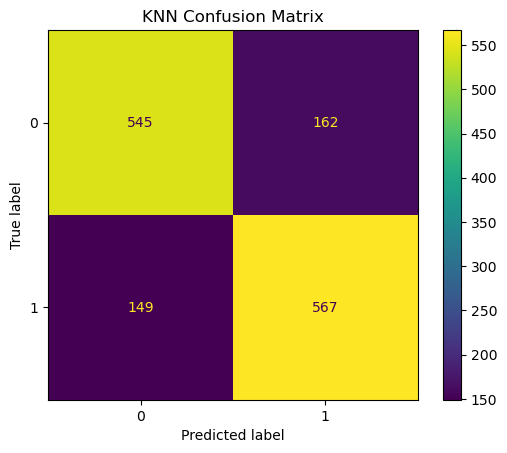

In [30]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions
y_pred = knn.predict(X_test_scaled)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.3f}")

# Classification report
print(classification_report(y_test, y_pred, digits=3))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("KNN Confusion Matrix")
plt.show()

In [31]:
for k in [3,5,7,9,11,15]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    preds = knn.predict(X_test_scaled)
    print(f"k={k}, accuracy={accuracy_score(y_test, preds):.3f}")

k=3, accuracy=0.764
k=5, accuracy=0.781
k=7, accuracy=0.770
k=9, accuracy=0.777
k=11, accuracy=0.777
k=15, accuracy=0.769
